# Singapore HDB Resale Market & Affordability Analysis

This project analyzes Singapore HDB resale transactions using data from the official data.gov.sg platform. 

The objective is to explore resale price trends and investigate how factors such as flat type, location, floor area, storey range and remaninf lease relate to resale prices. 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries loaded successfully!


## 1. Data Acquisition 

HDB resale tranaction data is retrievd from the official data.gov.sg API. 

The dataset covers resale flat transactions registered from January 2017 onwards. 

In [7]:
import requests

dataset_id = "d_8b84c4ee58e3cfc0ece0d773c8ca6abc"

url = "https://data.gov.sg/api/action/datastore_search"

params = {
    "resource_id": dataset_id,
    "limit": 5
}

response = requests.get(url, params=params)

print(response.status_code)

200


In [13]:
params = {
    "resource_id": dataset_id,
    "limit": 10000
}

response = requests.get(url, params=params)

print(response.status_code)

200


In [14]:
data = response.json()

df = pd.DataFrame(data["result"]["records"])

print(df.shape)

(10000, 12)


In [15]:
data["result"]["total"]

240807

In [16]:
all_records = []

batch_size = 10000

for offset in range(0, data["result"]["total"], batch_size):
    params = {
        "resource_id": dataset_id,
        "limit": batch_size,
        "offset": offset
    }

    response = requests.get(url, params=params)

    batch = response.json()["result"]["records"]
    all_records.extend(batch)

    print(f"Retrieved {len(all_records):,} records")

Retrieved 10,000 records
Retrieved 20,000 records
Retrieved 30,000 records
Retrieved 40,000 records
Retrieved 50,000 records
Retrieved 60,000 records
Retrieved 70,000 records
Retrieved 80,000 records
Retrieved 90,000 records
Retrieved 100,000 records
Retrieved 110,000 records
Retrieved 120,000 records
Retrieved 130,000 records
Retrieved 140,000 records
Retrieved 150,000 records
Retrieved 160,000 records
Retrieved 170,000 records
Retrieved 180,000 records
Retrieved 190,000 records
Retrieved 200,000 records
Retrieved 210,000 records
Retrieved 220,000 records
Retrieved 230,000 records
Retrieved 240,000 records
Retrieved 240,807 records


In [17]:
df = pd.DataFrame(all_records)

print(df.shape)

(240807, 12)


## 2. Initial Data Inspection 

The API rsponse is converted into a pandas DataFrame so that the transaction records can be examined and analyzed in a structured format. 

In [6]:
data = response.json()

data["result"]["records"]

[{'_id': 1,
  'month': '2017-01',
  'town': 'ANG MO KIO',
  'flat_type': '2 ROOM',
  'block': '406',
  'street_name': 'ANG MO KIO AVE 10',
  'storey_range': '10 TO 12',
  'floor_area_sqm': '44',
  'flat_model': 'Improved',
  'lease_commence_date': '1979',
  'remaining_lease': '61 years 04 months',
  'resale_price': '232000'},
 {'_id': 2,
  'month': '2017-01',
  'town': 'ANG MO KIO',
  'flat_type': '3 ROOM',
  'block': '108',
  'street_name': 'ANG MO KIO AVE 4',
  'storey_range': '01 TO 03',
  'floor_area_sqm': '67',
  'flat_model': 'New Generation',
  'lease_commence_date': '1978',
  'remaining_lease': '60 years 07 months',
  'resale_price': '250000'},
 {'_id': 3,
  'month': '2017-01',
  'town': 'ANG MO KIO',
  'flat_type': '3 ROOM',
  'block': '602',
  'street_name': 'ANG MO KIO AVE 5',
  'storey_range': '01 TO 03',
  'floor_area_sqm': '67',
  'flat_model': 'New Generation',
  'lease_commence_date': '1980',
  'remaining_lease': '62 years 05 months',
  'resale_price': '262000'},
 {'_id

In [8]:
import pandas as pd

df = pd.DataFrame(data["result"]["records"])

df

,_id,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,1,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44,Improved,1979,61 years 04 months,232000
1,2,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67,New Generation,1978,60 years 07 months,250000
2,3,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67,New Generation,1980,62 years 05 months,262000
3,4,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68,New Generation,1980,62 years 01 month,265000
4,5,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67,New Generation,1980,62 years 05 months,265000


## 3. Dataset Structure 

The dataset contains 12 column covering transaction details, flat characteristics, location, lease information and resale price.

The 'resale_price' variable will be used as the primary outcome for this analysis. Other variables will be explored to undertstadn theri relationship with resale prices. 

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   _id                  5 non-null      int64
 1   month                5 non-null      str  
 2   town                 5 non-null      str  
 3   flat_type            5 non-null      str  
 4   block                5 non-null      str  
 5   street_name          5 non-null      str  
 6   storey_range         5 non-null      str  
 7   floor_area_sqm       5 non-null      str  
 8   flat_model           5 non-null      str  
 9   lease_commence_date  5 non-null      str  
 10  remaining_lease      5 non-null      str  
 11  resale_price         5 non-null      str  
dtypes: int64(1), str(11)
memory usage: 612.0 bytes


In [10]:
df.shape

(5, 12)

In [11]:
df.columns

Index(['_id', 'month', 'town', 'flat_type', 'block', 'street_name',
       'storey_range', 'floor_area_sqm', 'flat_model', 'lease_commence_date',
       'remaining_lease', 'resale_price'],
      dtype='str')

## 4. Data Quality Checks

Before conducting the anlaysis, the dataset is chekced for missing values and data quality issues that may affect the results. 

### 4.1 Missing Values

The dataset is checked for missing values to identify incomplete records that may affect subsequent analysis. 

In [18]:
df.isnull().sum()

_id                    0
month                  0
town                   0
flat_type              0
block                  0
street_name            0
storey_range           0
floor_area_sqm         0
flat_model             0
lease_commence_date    0
remaining_lease        0
resale_price           0
dtype: int64

In [19]:
df.dtypes

_id                    int64
month                    str
town                     str
flat_type                str
block                    str
street_name              str
storey_range             str
floor_area_sqm           str
flat_model               str
lease_commence_date      str
remaining_lease          str
resale_price             str
dtype: object

In [20]:
df.head()

,_id,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,1,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44,Improved,1979,61 years 04 months,232000
1,2,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67,New Generation,1978,60 years 07 months,250000
2,3,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67,New Generation,1980,62 years 05 months,262000
3,4,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68,New Generation,1980,62 years 01 month,265000
4,5,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67,New Generation,1980,62 years 05 months,265000


### 4.2 Converting Numeric Variables

Several numerical variables are initially stored as text in the dataset. The 'floor_area_sqm', 'lease_commence_date' and 'resale_price' columns are converted to numeric data types to enable calculations and statistical analysis. 

In [21]:
df["floor_area_sqm"] = pd.to_numeric(df["floor_area_sqm"])
df["lease_commence_date"] = pd.to_numeric(df["lease_commence_date"])
df["resale_price"] = pd.to_numeric(df["resale_price"])

In [22]:
df.dtypes

_id                      int64
month                      str
town                       str
flat_type                  str
block                      str
street_name                str
storey_range               str
floor_area_sqm         float64
flat_model                 str
lease_commence_date      int64
remaining_lease            str
resale_price           float64
dtype: object

### 4.3 Converting Transaction Month

The 'month' column records the transaction registration month in 'YYYY-MM' format. It is converted from text into a datetime format to support chronological analysis and time-based visualizations.

In [23]:
df["month"] = pd.to_datetime(df["month"], format="%Y-%m")

In [24]:
df["month"].dtype

dtype('<M8[us]')

### 4.4 Standardizing Remaining Lease

The 'remaining_lease' column contains lease information in a text format, such as "61 years 04 months". To support quantitative analysis, the lease duration is converted into a numeric measure representing the approximate number of years remaining.

In [25]:
df["remaining_lease_years"] = (
    df["remaining_lease"]
    .str.extract(r"(\d+)\s+years")[0]
    .astype(int)
)

df["remaining_lease_months"] = (
    df["remaining_lease"]
    .str.extract(r"(\d+)\s+months")[0]
    .fillna(0)
    .astype(int)
)

In [26]:
df["remaining_lease_numeric"] = (
    df["remaining_lease_years"] + df["remaining_lease_months"] / 12
)

In [27]:
df[["remaining_lease", "remaining_lease_numeric"]].head()

,remaining_lease,remaining_lease_numeric
0,61 years 04 months,61.333333
1,60 years 07 months,60.583333
2,62 years 05 months,62.416667
3,62 years 01 month,62.000000
4,62 years 05 months,62.416667


The extracted year and month components are used to create a single continuous lease variable. The intermediate columns are removed after conversion to keep the dataset concise.

In [28]:
df = df.drop(columns=["remaining_lease_years", "remaining_lease_months"])

In [29]:
df.columns

Index(['_id', 'month', 'town', 'flat_type', 'block', 'street_name',
       'storey_range', 'floor_area_sqm', 'flat_model', 'lease_commence_date',
       'remaining_lease', 'resale_price', 'remaining_lease_numeric'],
      dtype='str')

### 4.5 Final Data Validation

A final check is performed to confirm that the cleaned dataset has the expected number of records and that the key numerical variables are ready for analysis.

In [30]:
print("Dataset shape:", df.shape)

print("\nKey numerical variables:")
print(df[["floor_area_sqm", "lease_commence_date", "resale_price", "remaining_lease_numeric"]].dtypes)

Dataset shape: (240807, 13)

Key numerical variables:
floor_area_sqm             float64
lease_commence_date          int64
resale_price               float64
remaining_lease_numeric    float64
dtype: object


## 5. Exploratory Data Analysis

The cleaned dataset is explored to identify key patterns and relationships in Singapore's HDB resale market. The analysis begins with the overall distribution of resale prices before examining differences across time, flat characteristics and locations.

### 5.1 Overall Resale Price Distribution

The distribution of resale prices is examined to understand the typical transaction values and identify the overall spread of prices in the dataset. This provides a baseline for interpreting differences across flat types, locations and other property characteristics.

In [31]:
df["resale_price"].describe()

count    2.408070e+05
mean     5.351789e+05
std      1.925109e+05
min      1.400000e+05
25%      3.900000e+05
50%      5.050000e+05
75%      6.420000e+05
max      1.728000e+06
Name: resale_price, dtype: float64

To visualize the distribution of resale prices, a histogram is used to show how frequently transactions occur across different price ranges.

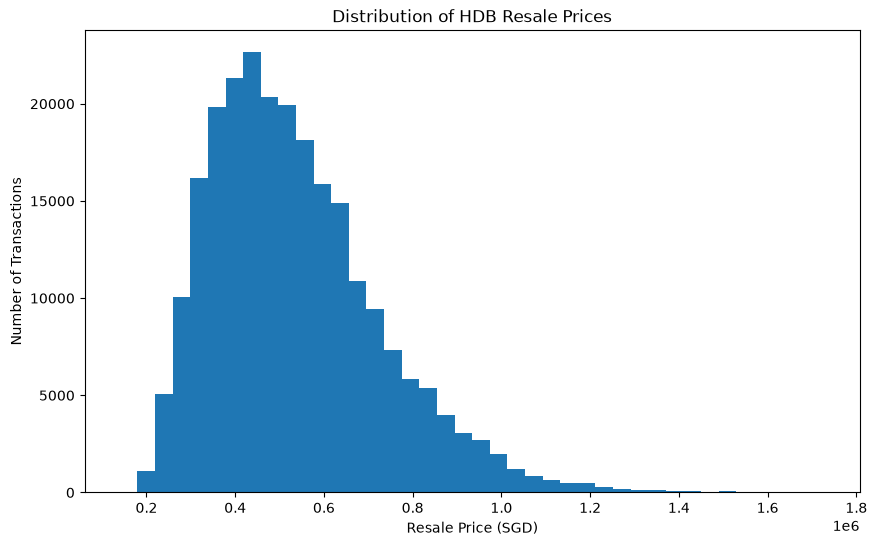

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(df["resale_price"], bins=40)

plt.title("Distribution of HDB Resale Prices")
plt.xlabel("Resale Price (SGD)")
plt.ylabel("Number of Transactions")

plt.show()

### 5.2 Resale Price Trends Over Time

The monthly median resale price is examined to identify changes in HDB resale prices over time. The median is used instead of the mean to reduce the influence of unusually high-priced transactions.

In [33]:
monthly_prices = (
    df.groupby("month")["resale_price"]
    .median()
    .reset_index()
)

monthly_prices.head()

,month,resale_price
0,2017-01-01,405000.0
1,2017-02-01,415000.0
2,2017-03-01,415000.0
3,2017-04-01,408000.0
4,2017-05-01,410000.0


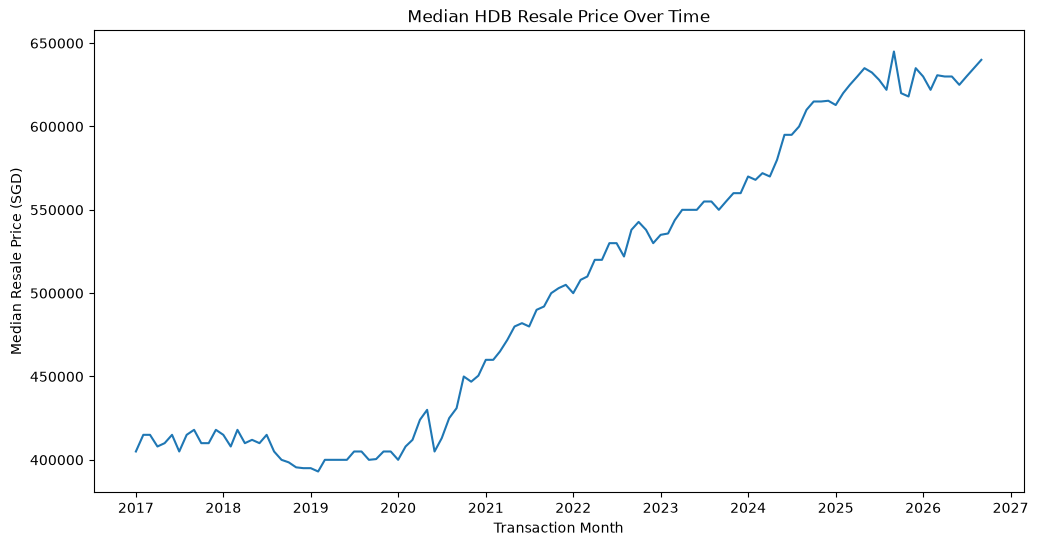

In [34]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_prices["month"],
    monthly_prices["resale_price"]
)

plt.title("Median HDB Resale Price Over Time")
plt.xlabel("Transaction Month")
plt.ylabel("Median Resale Price (SGD)")

plt.show()

### 5.3 Resale Price by Flat Type

The median resale price is compared across flat types to examine differences in transaction values. The median is used to reduce the influence of unusually high or low-priced transactions within each flat type.

In [35]:
flat_type_prices = (
    df.groupby("flat_type")["resale_price"]
    .median()
    .sort_values(ascending=False)
    .reset_index()
)

flat_type_prices

,flat_type,resale_price
0,MULTI-GENERATION,848000.0
1,EXECUTIVE,728000.0
2,5 ROOM,615000.0
3,4 ROOM,511000.0
4,3 ROOM,360000.0
5,2 ROOM,315000.0
6,1 ROOM,212500.0


The results are visualized using a bar chart to make differences in median resale prices across flat types easier to compare.

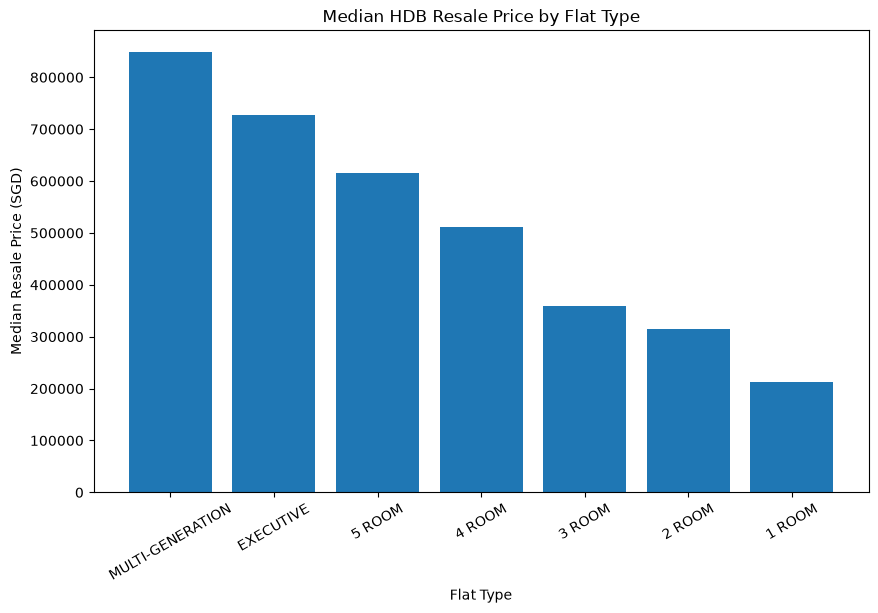

In [36]:
plt.figure(figsize=(10, 6))

plt.bar(
    flat_type_prices["flat_type"],
    flat_type_prices["resale_price"]
)

plt.title("Median HDB Resale Price by Flat Type")
plt.xlabel("Flat Type")
plt.ylabel("Median Resale Price (SGD)")

plt.xticks(rotation=30)

plt.show()

### 5.4 Resale Price by Town

The median resale price is compared across HDB towns to examine geographic differences in resale transaction values. Comparing towns provides an initial view of how location may be associated with resale prices.

In [37]:
town_prices = (
    df.groupby("town")["resale_price"]
    .median()
    .sort_values(ascending=False)
    .reset_index()
)

town_prices

,town,resale_price
0,BUKIT TIMAH,792500.0
1,BISHAN,700000.0
2,QUEENSTOWN,675000.0
3,BUKIT MERAH,662000.0
4,PASIR RIS,580000.0
5,CENTRAL AREA,575000.0
6,KALLANG/WHAMPOA,575000.0
7,TAMPINES,552000.0
8,SERANGOON,535000.0
9,PUNGGOL,535000.0


The results are visualized using a horizontal bar chart to allow the median resale prices of all towns to be compared clearly.

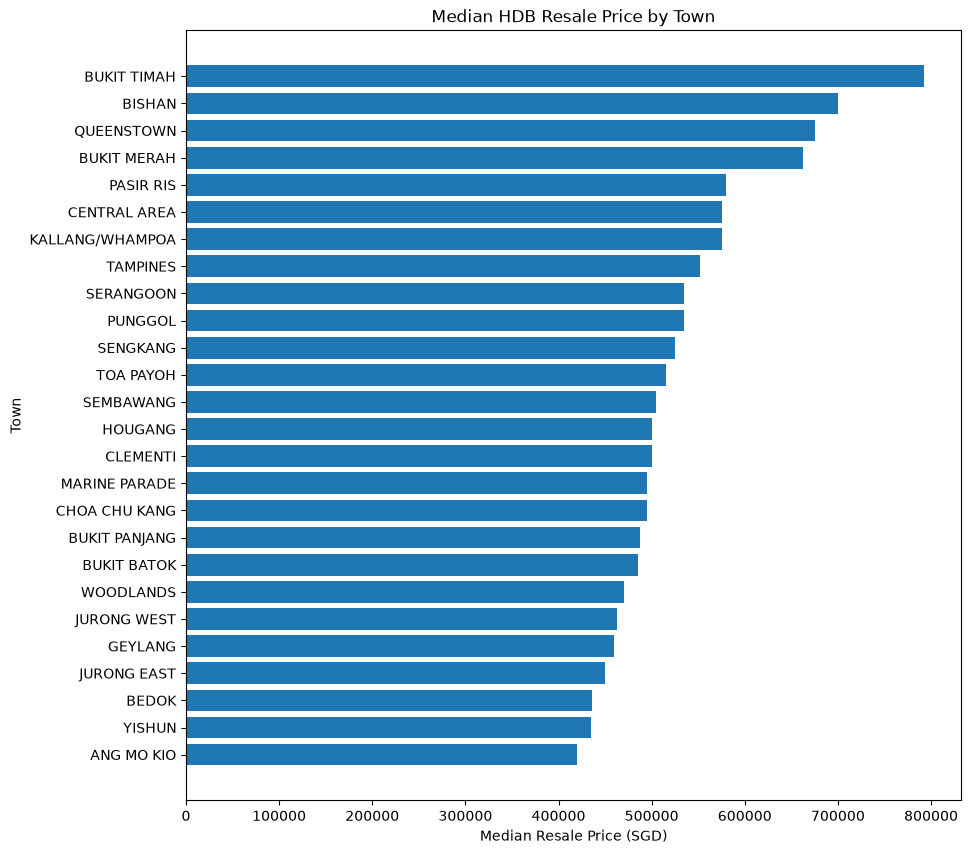

In [38]:
plt.figure(figsize=(10, 10))

plt.barh(
    town_prices["town"],
    town_prices["resale_price"]
)

plt.title("Median HDB Resale Price by Town")
plt.xlabel("Median Resale Price (SGD)")
plt.ylabel("Town")

plt.gca().invert_yaxis()

plt.show()

### 5.5 Price per Square Metre

Resale price per square metre is calculated to provide a size-adjusted measure of property value. This allows transactions involving flats of different sizes to be compared on a more consistent basis.

In [39]:
df["price_per_sqm"] = (
    df["resale_price"] / df["floor_area_sqm"]
)

df[["resale_price", "floor_area_sqm", "price_per_sqm"]].head()

,resale_price,floor_area_sqm,price_per_sqm
0,232000.0,44.0,5272.727273
1,250000.0,67.0,3731.343284
2,262000.0,67.0,3910.447761
3,265000.0,68.0,3897.058824
4,265000.0,67.0,3955.223881


In [40]:
df["price_per_sqm"].describe()

count    240807.000000
mean       5596.520287
std        1680.822520
min        2089.552239
25%        4409.090909
50%        5318.181818
75%        6356.589147
max       16148.936170
Name: price_per_sqm, dtype: float64

The median price per square metre is compared across HDB towns to examine geographic differences after accounting for flat size. This provides a more size-adjusted comparison of property values than total resale price alone.

In [41]:
town_psm = (
    df.groupby("town")["price_per_sqm"]
    .median()
    .sort_values(ascending=False)
    .reset_index()
)

town_psm

,town,price_per_sqm
0,CENTRAL AREA,7710.843373
1,QUEENSTOWN,7537.414966
2,BUKIT MERAH,6982.758621
3,BUKIT TIMAH,6792.156120
4,BISHAN,6428.571429
5,MARINE PARADE,6341.463415
6,KALLANG/WHAMPOA,6276.923077
7,TOA PAYOH,5801.980198
8,CLEMENTI,5791.044776
9,PUNGGOL,5741.071429


The results are visualized using a horizontal bar chart to compare median price per square metre across HDB towns.

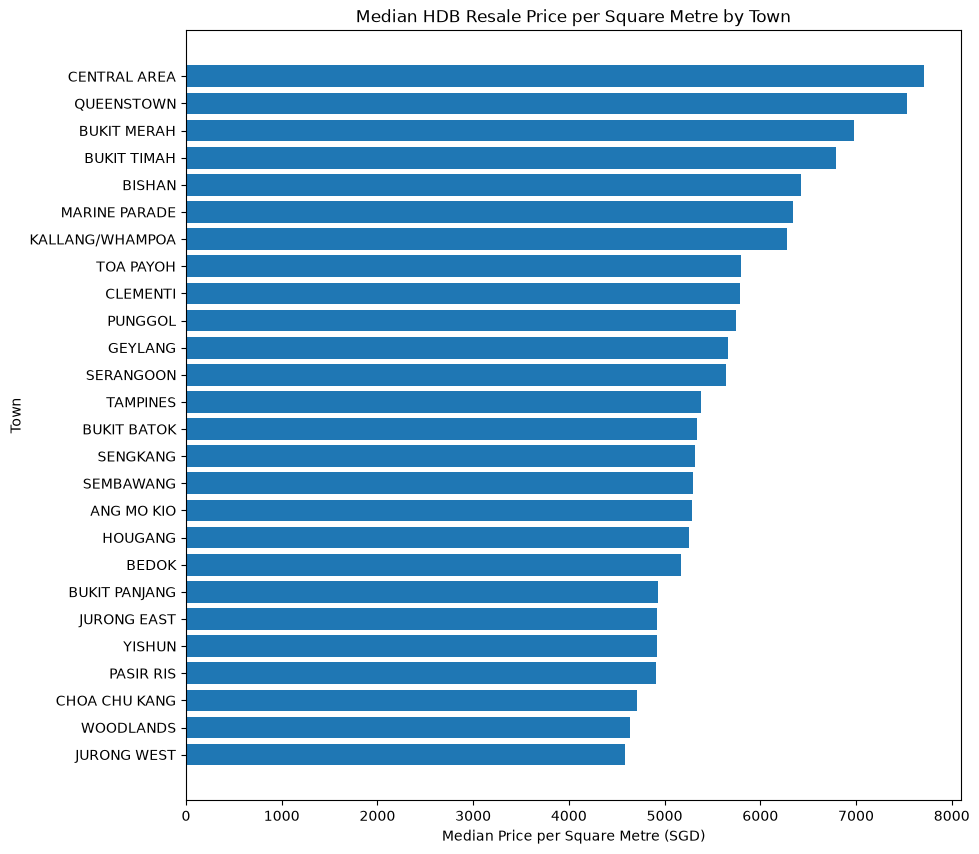

In [42]:
plt.figure(figsize=(10, 10))

plt.barh(
    town_psm["town"],
    town_psm["price_per_sqm"]
)

plt.title("Median HDB Resale Price per Square Metre by Town")
plt.xlabel("Median Price per Square Metre (SGD)")
plt.ylabel("Town")

plt.gca().invert_yaxis()

plt.show()

### 5.6 Remaining Lease vs Resale Price

The relationship between remaining lease and resale price is examined to explore whether flats with different remaining lease durations tend to have different transaction values.

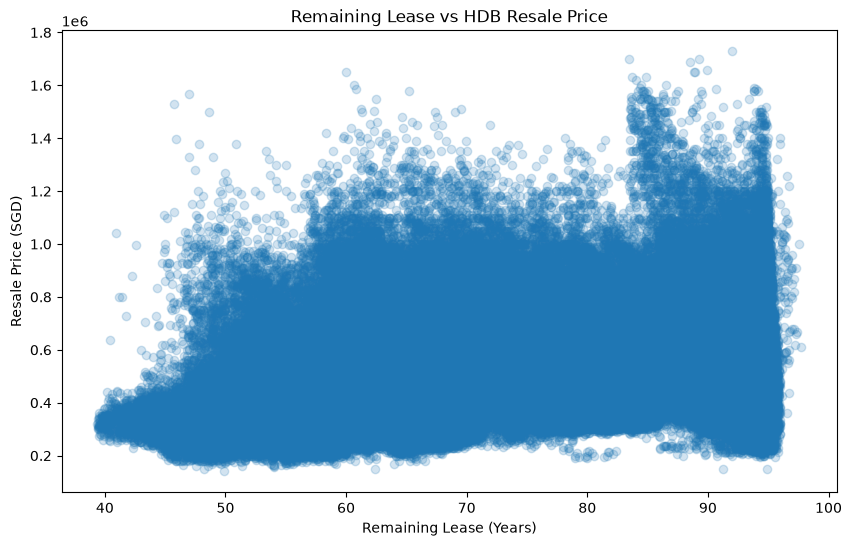

In [43]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["remaining_lease_numeric"],
    df["resale_price"],
    alpha=0.2
)

plt.title("Remaining Lease vs HDB Resale Price")
plt.xlabel("Remaining Lease (Years)")
plt.ylabel("Resale Price (SGD)")

plt.show()

To make the relationship easier to interpret, transactions are grouped by remaining lease year and the median resale price is calculated for each group. This reduces the effect of individual transaction-level variation while retaining the overall relationship between lease duration and resale price.

In [44]:
lease_price = (
    df.groupby(df["remaining_lease_numeric"].round())["resale_price"]
    .median()
    .reset_index()
)

lease_price.head()

,remaining_lease_numeric,resale_price
0,39.0,316500.0
1,40.0,329000.0
2,41.0,340000.0
3,42.0,333000.0
4,43.0,342000.0


The grouped results are visualized to examine the overall pattern between remaining lease duration and median resale price.

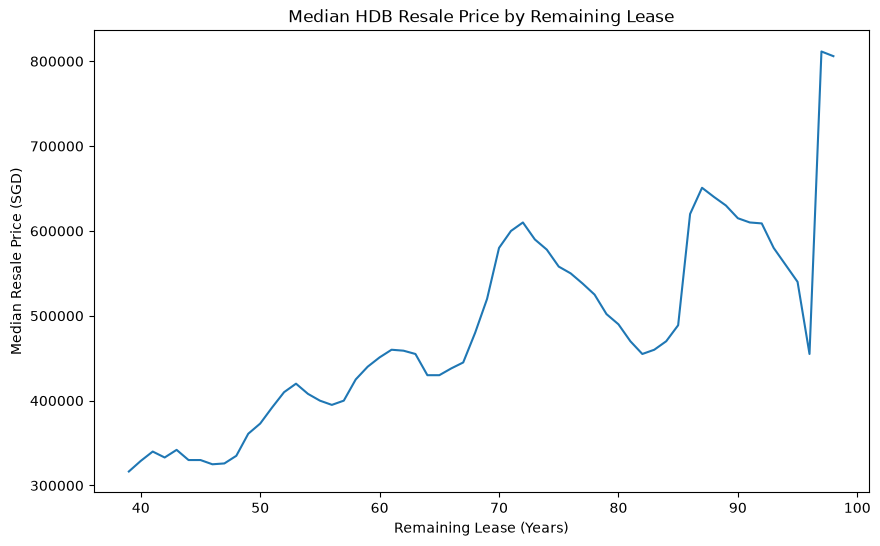

In [45]:
plt.figure(figsize=(10, 6))

plt.plot(
    lease_price["remaining_lease_numeric"],
    lease_price["resale_price"]
)

plt.title("Median HDB Resale Price by Remaining Lease")
plt.xlabel("Remaining Lease (Years)")
plt.ylabel("Median Resale Price (SGD)")

plt.show()

To complement the visual analysis, the Pearson correlation between remaining lease and resale price is calculated. This measures the strength and direction of their linear association.

In [46]:
lease_price_correlation = df[
    ["remaining_lease_numeric", "resale_price"]
].corr()

lease_price_correlation

,remaining_lease_numeric,resale_price
remaining_lease_numeric,1.000000,0.300027
resale_price,0.300027,1.000000


The correlation between remaining lease and resale price is approximately 0.30, indicating a positive but modest linear association. This suggests that flats with longer remaining leases tend to have higher resale prices. However the relationship is not strong enough to explain resale prices on its own. Other factors, such as flat size, flat type, location, and transaction period are likely to contribute to differences in resale prices.

## 6. Key Findings from Initial Exploration

The initial exploration highlights several patterns in Singapore's HDB resale market:

- Resale prices vary substantially across transactions, with a wide overall price distribution.
- Median resale prices have changed over time, indicating that transaction period is an important consideration when analysing the resale market.
- Median resale prices differ considerably across flat types and HDB towns.
- Price per square metre provides a more size-adjusted comparison of resale values across towns.
- Remaining lease has a positive but modest linear association with resale price, suggesting that lease duration is one of the several factors associated with resale values.

These findings provide a basis for deeper analysis of the factors associated with HDB resale prices.

## 7. Export Cleaned Dataset

The cleaned dataset is exported as a CSV file for use in subsequent analysis notebooks. This avoids repeating the data acquisition and cleaning steps. 

In [47]:
df.to_csv("../data/hdb_resale_cleaned.csv", index=False)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.
